# Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

# Load Libraries

In [3]:
library(tidyverse)
library(data.table)
library(qvalue)
library(pheatmap)
library(gridExtra)
library(grid)
library(RColorBrewer)

# Set Variables

In [4]:
# Set variables for I/O and thresholds
deg_dir <- "05_DEGs"
out_dir <- "06_Global_Transcriptome"
fdr_cut <- 0.01
nominal_cut <- 0.01

In [5]:
# Create dirs as needed
dir.create(out_dir, showWarnings = FALSE)
dir.create(file.path(out_dir, "per_contrast"), showWarnings = FALSE)

# Load Data

In [6]:
# DEG results
csv_files <- list.files(deg_dir, pattern = "_results\\.csv$", full.names = TRUE)

if (length(csv_files) == 0) stop("No *_results.csv files found in ", deg_dir)

contrast_names <- csv_files %>%
  basename() %>%
  sub("_results\\.csv$", "", .)

print(data.frame(contrast = contrast_names, file = basename(csv_files)))
message("Total files: ", length(csv_files))

                       contrast                                      file
1 MUT_Guide6_vs_MUT_NonEffector MUT_Guide6_vs_MUT_NonEffector_results.csv
2          MUT_Guide6_vs_MUT_NT          MUT_Guide6_vs_MUT_NT_results.csv
3           MUT_Guide6_vs_WT_NT           MUT_Guide6_vs_WT_NT_results.csv
4     MUT_NonEffector_vs_MUT_NT     MUT_NonEffector_vs_MUT_NT_results.csv
5      MUT_NonEffector_vs_WT_NT      MUT_NonEffector_vs_WT_NT_results.csv
6               MUT_NT_vs_WT_NT               MUT_NT_vs_WT_NT_results.csv


Total files: 6



In [7]:
# Confirm data structure
test_file <- csv_files[1]
test_dt   <- fread(test_file, data.table = FALSE)
str(test_dt)
head(test_dt, 3)

'data.frame':	16660 obs. of  7 variables:
 $ V1       : chr  "AQP4" "DUSP4" "ITGA3" "MLC1" ...
 $ logFC    : num  4.04 -2.11 -2.07 1.87 1.69 ...
 $ AveExpr  : num  7.3 6.49 5.06 8.09 6.3 ...
 $ t        : num  23.9 -21.6 -21.2 20.5 20 ...
 $ P.Value  : num  6.16e-15 3.59e-14 5.00e-14 8.90e-14 1.36e-13 ...
 $ adj.P.Val: num  1.03e-10 2.78e-10 2.78e-10 3.71e-10 3.86e-10 ...
 $ B        : num  24.3 22.7 22.2 21.8 21.4 ...


,V1,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AQP4,4.040767,7.299996,23.91333,6.164749e-15,1.027047e-10,24.26125
2,DUSP4,-2.114951,6.486410,-21.58206,3.585324e-14,2.779088e-10,22.66052
3,ITGA3,-2.072613,5.056516,-21.16515,5.004360e-14,2.779088e-10,22.22082


In [8]:
# Read all CSVs into a named list
res_list <- setNames(
  lapply(csv_files, function(f) {
    dt <- fread(f, data.table = FALSE)
    if (!"gene" %in% colnames(dt) && !is.numeric(dt[[1]])) {
      rownames(dt) <- dt[[1]]
      dt <- dt[, -1, drop = FALSE]
    }
    need <- c("logFC", "AveExpr", "t", "P.Value", "adj.P.Val")
    miss <- setdiff(need, colnames(dt))
    if (length(miss)) stop("Missing columns in ", basename(f), ": ",
                           paste(miss, collapse = ", "))
    dt
  }),
  contrast_names
)

# View
message("Loaded ", length(res_list), " contrasts")
sapply(res_list, nrow)
sapply(res_list, function(x) sum(is.finite(x$P.Value)))

Loaded 6 contrasts



MUT_Guide6_vs_MUT_NonEffector          MUT_Guide6_vs_MUT_NT 
                        16660                         16660 
          MUT_Guide6_vs_WT_NT     MUT_NonEffector_vs_MUT_NT 
                        16660                         16660 
     MUT_NonEffector_vs_WT_NT               MUT_NT_vs_WT_NT 
                        16660                         16660

MUT_Guide6_vs_MUT_NonEffector          MUT_Guide6_vs_MUT_NT 
                        16660                         16660 
          MUT_Guide6_vs_WT_NT     MUT_NonEffector_vs_MUT_NT 
                        16660                         16660 
     MUT_NonEffector_vs_WT_NT               MUT_NT_vs_WT_NT 
                        16660                         16660

# Functions

In [9]:
stouffer_z <- function(t_vals, weights = NULL) {
  t_vals <- t_vals[is.finite(t_vals)]
  if (length(t_vals) == 0) return(NA_real_)
  if (is.null(weights)) weights <- rep(1, length(t_vals))
  sum(t_vals * weights) / sqrt(sum(weights^2))
}

In [10]:
safe_pi0 <- function(p) {
  p <- p[is.finite(p)]
  p <- pmin(pmax(p, 1e-300), 1 - 1e-16)
  tryCatch({
    q <- qvalue(p)
    list(pi0 = q$pi0, prop_de = 1 - q$pi0)
  }, error = function(e) list(pi0 = NA_real_, prop_de = NA_real_))
}

In [11]:
prop_true_null <- function(p, lambda = seq(0.05, 0.95, 0.05)) {
  p <- p[is.finite(p)]
  if (length(p) < 100) return(NA_real_)
  pi0_est <- sapply(lambda, function(l) mean(p > l) / (1 - l))
  tryCatch({
    min(1, predict(smooth.spline(lambda, pi0_est, df = 3),
                   x = max(lambda))$y)
  }, error = function(e) NA_real_)
}

# Global Shift Summary

In [12]:
# Run per contrast
summary_tbl <- map_dfr(seq_along(res_list), function(i) {
  res <- res_list[[i]]
  nm  <- names(res_list)[i]
  p   <- res$P.Value
  lfc <- res$logFC
  tst <- res$t

  pi_est <- safe_pi0(p)
  z_val  <- stouffer_z(tst)

  tibble(
    contrast        = nm,
    n_genes         = sum(is.finite(p)),
    median_logFC    = median(lfc, na.rm = TRUE),
    mean_logFC      = mean(lfc,   na.rm = TRUE),
    sd_logFC        = sd(lfc, na.rm = TRUE),
    IQR_logFC       = IQR(lfc, na.rm = TRUE),
    stouffer_Z      = z_val,
    stouffer_p      = 2 * pnorm(-abs(z_val)),
    prop_up         = mean(lfc > 0, na.rm = TRUE),
    binom_p_updown  = tryCatch(
      binom.test(sum(lfc > 0, na.rm = TRUE),
                 sum(is.finite(lfc)))$p.value,
      error = function(e) NA_real_),
    wilcox_p        = tryCatch(
      wilcox.test(lfc, mu = 0)$p.value,
      error = function(e) NA_real_),
    ks_p            = tryCatch(
      ks.test(p, "punif")$p.value,
      error = function(e) NA_real_),
    pi0_qvalue      = pi_est$pi0,
    prop_true_de    = pi_est$prop_de,
    pi0_storey      = prop_true_null(p),
    n_p_0.05        = sum(p < 0.05, na.rm = TRUE),
    n_p_0.01        = sum(p < 0.01, na.rm = TRUE),
    n_p_0.001       = sum(p < 0.001, na.rm = TRUE),
    n_fdr_0.05      = sum(res$adj.P.Val < 0.05, na.rm = TRUE),
    n_fdr_0.10      = sum(res$adj.P.Val < 0.10, na.rm = TRUE),
    n_fdr_0.25      = sum(res$adj.P.Val < 0.25, na.rm = TRUE)
  )
})

summary_tbl <- summary_tbl %>%
  mutate(global_shift_score = stouffer_Z,
         rank_shift         = rank(-abs(global_shift_score))) %>%
  arrange(rank_shift)

print(as.data.frame(summary_tbl %>%
  select(contrast, n_genes, median_logFC, stouffer_Z, stouffer_p,
         ks_p, prop_true_de, n_fdr_0.05, n_p_0.01)))

                       contrast n_genes median_logFC stouffer_Z   stouffer_p
1          MUT_Guide6_vs_MUT_NT   16660  0.022313563  21.026072 3.787412e-98
2               MUT_NT_vs_WT_NT   16660 -0.011944564 -16.300961 9.715327e-60
3     MUT_NonEffector_vs_MUT_NT   16660 -0.024072958   7.460266 8.634793e-14
4 MUT_Guide6_vs_MUT_NonEffector   16660  0.001068885   5.977793 2.261814e-09
5           MUT_Guide6_vs_WT_NT   16660 -0.028586074   5.193445 2.064380e-07
6      MUT_NonEffector_vs_WT_NT   16660 -0.003580209  -3.315016 9.163804e-04
  ks_p prop_true_de n_fdr_0.05 n_p_0.01
1    0    0.7381119       8557     7334
2    0    0.6170191       6229     5538
3    0    0.6756910       7719     6713
4    0    0.6813960       7348     6357
5    0    0.7628951       9548     8323
6    0    0.7364969       8847     7718


In [13]:
# Save
out_file <- file.path(out_dir, "Summary Metrics", "summary_metrics.csv")
dir.create(dirname(out_file), recursive = TRUE, showWarnings = FALSE)

write.csv(summary_tbl, out_file, row.names = FALSE)
message("Wrote ", out_file)

Wrote 06_Global_Transcriptome/Summary Metrics/summary_metrics.csv



# Plot Global Shift

In [14]:
# Covnert to long data format
p_hist_data <- map_dfr(seq_along(res_list), function(i) {
  tibble(contrast = names(res_list)[i], p = res_list[[i]]$P.Value)
})

lfc_data <- map_dfr(seq_along(res_list), function(i) {
  tibble(contrast = names(res_list)[i], logFC = res_list[[i]]$logFC)
})

message("p_hist_data rows: ", nrow(p_hist_data))
message("lfc_data rows: ",    nrow(lfc_data))

p_hist_data rows: 99960

lfc_data rows: 99960



✔ Created directory: 06_Global_Transcriptome/P-Value Based Outputs/P-Value Histogram Distribution.



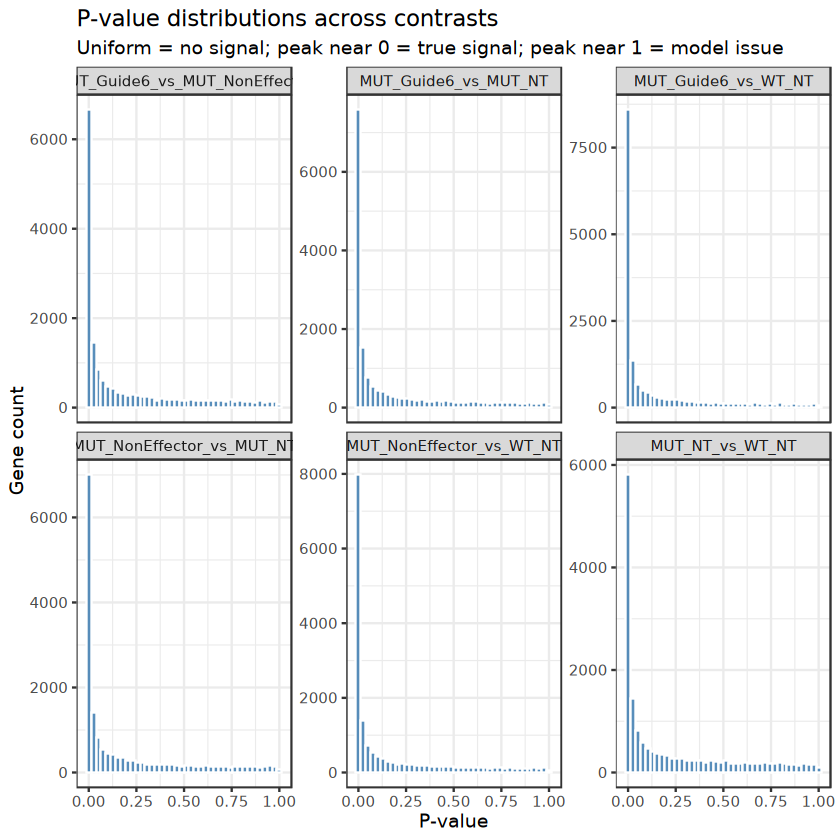

In [15]:
# Faceted p-value histograms
p_hist_plot <- ggplot(p_hist_data, aes(x = p)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white", alpha = 0.9) +
  facet_wrap(~ contrast, scales = "free_y", ncol = 3) +
  labs(title = "P-value distributions across contrasts",
       subtitle = "Uniform = no signal; peak near 0 = true signal; peak near 1 = model issue",
       x = "P-value", y = "Gene count") +
  theme_bw(base_size = 11)

# Save
out_file <- file.path(
  out_dir,
  "P-Value Based Outputs",
  "P-Value Histogram Distribution",
  "pvalue_histograms.pdf"
)

ggsave(out_file, p_hist_plot, width = 12, height = 8, create.dir = TRUE)

print(p_hist_plot)

In [16]:
# Histogram per contrast
hist_dir <- file.path(
  out_dir,
  "P-Value Based Outputs",
  "P-Value Histogram Distribution"
)

dir.create(hist_dir, recursive = TRUE, showWarnings = FALSE)

walk(seq_along(res_list), function(i) {
  nm <- names(res_list)[i]
  df <- tibble(p = res_list[[i]]$P.Value)

  g <- ggplot(df, aes(x = p)) +
    geom_histogram(bins = 40, fill = "steelblue", color = "white") +
    labs(title = nm, x = "P-value", y = "Count") +
    theme_bw()

  ggsave(
    file.path(hist_dir, paste0(gsub("[/ ]", "_", nm), "_pvalue_hist.pdf")),
    g, width = 5, height = 4,
    create.dir = TRUE
  )
})
message("Wrote per-contrast p-value histograms to ", hist_dir)

Wrote per-contrast p-value histograms to 06_Global_Transcriptome/P-Value Based Outputs/P-Value Histogram Distribution



✔ Created directory: 06_Global_Transcriptome/logFC Based Outputs.



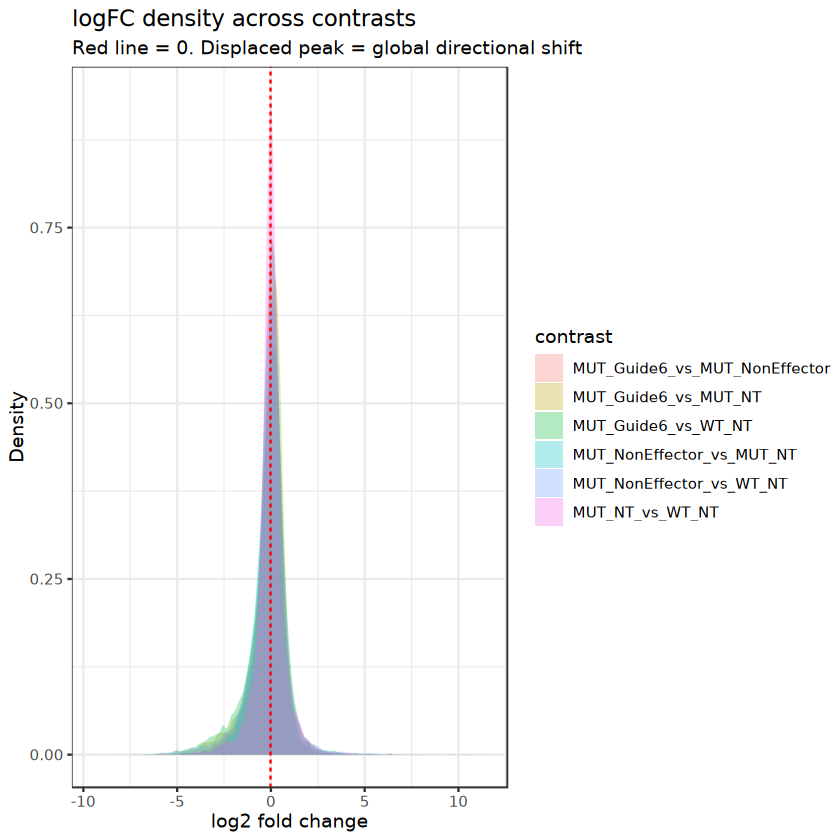

In [17]:
# logFC density
density_plot <- ggplot(lfc_data, aes(x = logFC, fill = contrast)) +
  geom_density(alpha = 0.3, color = NA) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "red") +
  labs(title = "logFC density across contrasts",
       subtitle = "Red line = 0. Displaced peak = global directional shift",
       x = "log2 fold change", y = "Density") +
  theme_bw(base_size = 11)

# Save
out_file <- file.path(
  out_dir,
  "logFC Based Outputs",
  "lfc_density.pdf"
)

ggsave(out_file,
       density_plot, width = 10, height = 6, create.dir = TRUE)
print(density_plot)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


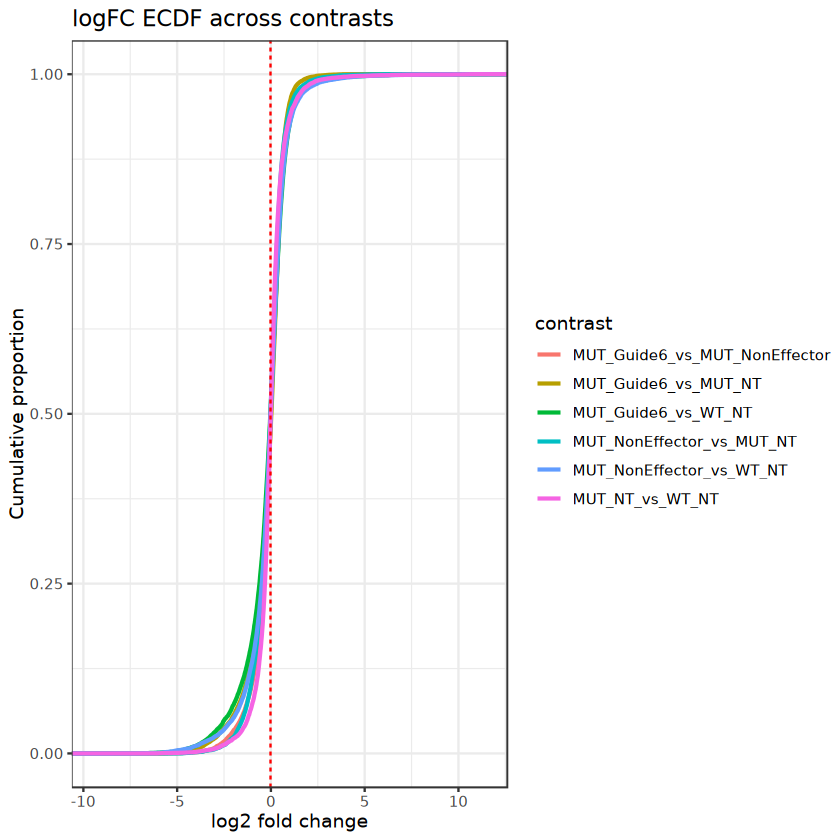

In [18]:
# logFC ECDF
ecdf_plot <- ggplot(lfc_data, aes(x = logFC, color = contrast)) +
  stat_ecdf(size = 0.9) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "red") +
  labs(title = "logFC ECDF across contrasts",
       x = "log2 fold change", y = "Cumulative proportion") +
  theme_bw(base_size = 11)

# Save
out_file <- file.path(
  out_dir,
  "logFC Based Outputs",
  "lfc_ecdf.pdf"
)

ggsave(out_file,
       ecdf_plot, width = 10, height = 6)
print(ecdf_plot)

✔ Created directory: 06_Global_Transcriptome/P-Value Based Outputs/q-value pi0 Estimates.



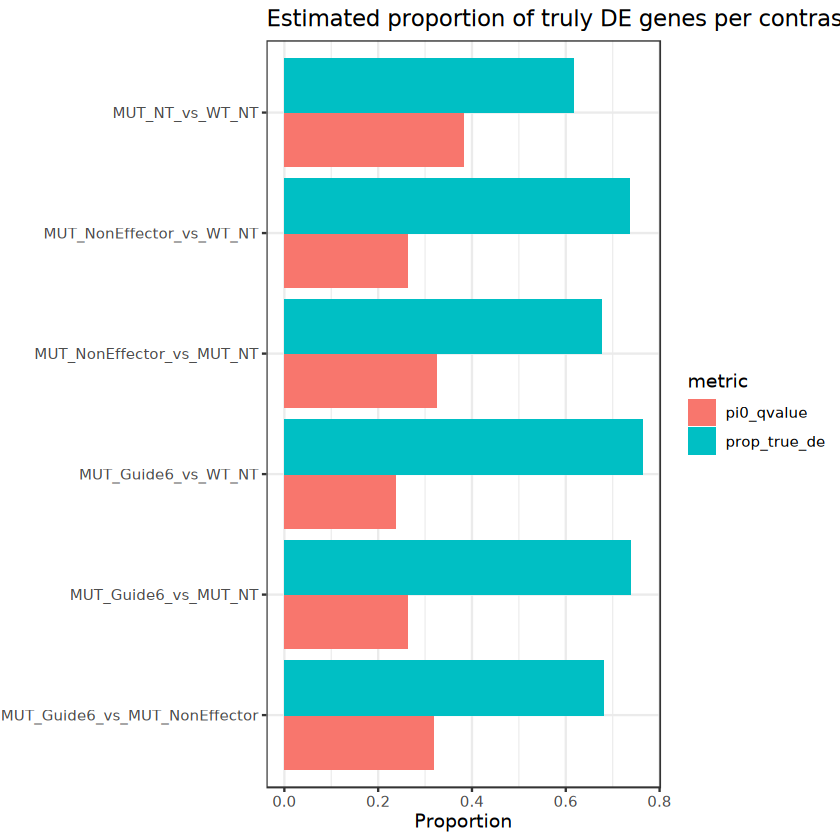

In [19]:
# pi0 / prop true DE
pi0_plot <- summary_tbl %>%
  select(contrast, pi0_qvalue, prop_true_de) %>%
  pivot_longer(-contrast, names_to = "metric", values_to = "value") %>%
  ggplot(aes(x = reorder(contrast, value), y = value, fill = metric)) +
  geom_col(position = "dodge") +
  coord_flip() +
  labs(title = "Estimated proportion of truly DE genes per contrast",
       x = NULL, y = "Proportion") +
  theme_bw(base_size = 11)

# Save
out_file <- file.path(
  out_dir,
  "P-Value Based Outputs",
  "q-value pi0 Estimates",
  "qvalue_pi0.pdf"
)

ggsave(out_file,
       pi0_plot, width = 10, height = 6, create.dir = TRUE)
print(pi0_plot)

In [20]:
# Build common gene set and logFC matrix
common_genes <- Reduce(intersect, lapply(res_list, rownames))
message("Common genes across all contrasts: ", length(common_genes))

if (length(common_genes) < 100) {
  warning("Fewer than 100 common genes — check gene ID consistency.")
}

lfc_mat <- sapply(res_list, function(x) x[common_genes, "logFC"])
p_mat   <- sapply(res_list, function(x) x[common_genes, "P.Value"])
rownames(lfc_mat) <- common_genes
rownames(p_mat)   <- common_genes

dim(lfc_mat)

Common genes across all contrasts: 16660



[1] 16660     6

In [21]:
# logFC correlation heatmap
lfc_cor <- cor(lfc_mat, method = "spearman", use = "pairwise.complete.obs")

print(round(lfc_cor, 2))

                              MUT_Guide6_vs_MUT_NonEffector
MUT_Guide6_vs_MUT_NonEffector                          1.00
MUT_Guide6_vs_MUT_NT                                   0.50
MUT_Guide6_vs_WT_NT                                    0.41
MUT_NonEffector_vs_MUT_NT                             -0.29
MUT_NonEffector_vs_WT_NT                              -0.31
MUT_NT_vs_WT_NT                                       -0.08
                              MUT_Guide6_vs_MUT_NT MUT_Guide6_vs_WT_NT
MUT_Guide6_vs_MUT_NonEffector                 0.50                0.41
MUT_Guide6_vs_MUT_NT                          1.00                0.73
MUT_Guide6_vs_WT_NT                           0.73                1.00
MUT_NonEffector_vs_MUT_NT                     0.58                0.40
MUT_NonEffector_vs_WT_NT                      0.33                0.64
MUT_NT_vs_WT_NT                              -0.15                0.44
                              MUT_NonEffector_vs_MUT_NT
MUT_Guide6_vs_MUT_NonEffect

agg_record_1864911060 
                    2

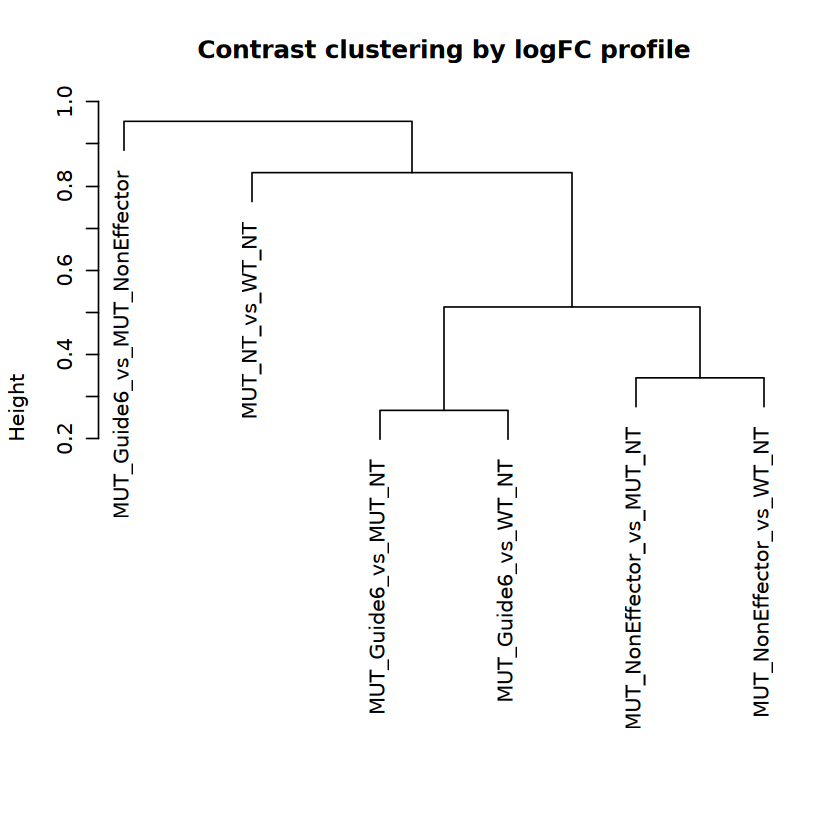

In [22]:
# Contrast clustering dendrogram
out_file <- file.path(
  out_dir,
  "logFC Based Outputs",
  "contrast_clustering.pdf"
)

pdf(out_file, width = 8, height = 6)
hc <- hclust(as.dist(1 - lfc_cor), method = "average")
plot(hc, main = "Contrast clustering by logFC profile",
     xlab = "", sub = "")
dev.off()

plot(hc, main = "Contrast clustering by logFC profile", xlab = "", sub = "")

✔ Created directory: 06_Global_Transcriptome/Shift Based Outputs.



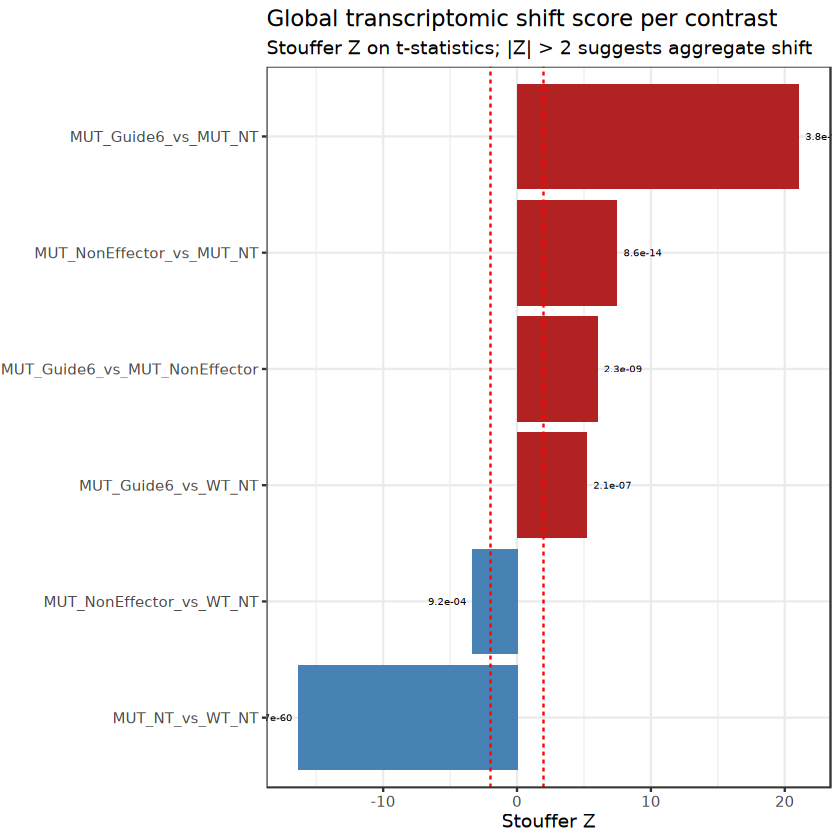

In [23]:
# Ranked global shift score
rank_plot <- summary_tbl %>%
  mutate(
    contrast        = fct_reorder(contrast, global_shift_score),
    label           = formatC(stouffer_p, format = "e", digits = 1),
    label_x         = ifelse(global_shift_score > 0,
                             global_shift_score + 0.5,
                             global_shift_score - 0.5)
  ) %>%
  ggplot(aes(x = contrast, y = global_shift_score, fill = global_shift_score > 0)) +
  geom_col() +
  geom_text(aes(y = label_x, label = label), hjust = ifelse(
    summary_tbl$global_shift_score > 0, 0, 1), size = 2) +
  coord_flip() +
  geom_hline(yintercept = c(-2, 2), linetype = "dashed", color = "red") +
  scale_fill_manual(values = c("TRUE" = "firebrick", "FALSE" = "steelblue"),
                    guide = "none") +
  labs(title = "Global transcriptomic shift score per contrast",
       subtitle = "Stouffer Z on t-statistics; |Z| > 2 suggests aggregate shift",
       x = NULL, y = "Stouffer Z") +
  theme_bw(base_size = 11)

# Save
out_file <- file.path(
  out_dir,
  "Shift Based Outputs",
  "transcriptome_shift_rank.pdf"
)

ggsave(out_file,
       rank_plot, width = 12, height = 5, create.dir = TRUE)
print(rank_plot)

In [24]:
# Global shift by expression decile
bin_shift <- map_dfr(seq_along(res_list), function(i) {
  res <- res_list[[i]]
  nm  <- names(res_list)[i]
  res <- res[is.finite(res$AveExpr) & is.finite(res$t), ]
  dec <- cut(res$AveExpr,
             breaks = quantile(res$AveExpr, 0:10/10, na.rm = TRUE),
             labels = FALSE, include.lowest = TRUE)
  tibble(contrast = nm, decile = dec, t = res$t) %>%
    group_by(contrast, decile) %>%
    summarise(
      n          = n(),
      mean_abs_t = mean(abs(t), na.rm = TRUE),
      stouffer_Z = sum(t, na.rm = TRUE) / sqrt(n()),
      .groups    = "drop"
    )
})

head(bin_shift)

contrast,decile,n,mean_abs_t,stouffer_Z
<chr>,<int>,<int>,<dbl>,<dbl>
MUT_Guide6_vs_MUT_NonEffector,1,1666,1.749167,-31.947620
MUT_Guide6_vs_MUT_NonEffector,2,1666,1.933498,-23.197170
MUT_Guide6_vs_MUT_NonEffector,3,1666,2.225143,-8.905097
MUT_Guide6_vs_MUT_NonEffector,4,1666,2.553222,4.460294
MUT_Guide6_vs_MUT_NonEffector,5,1666,2.749483,-0.698317
MUT_Guide6_vs_MUT_NonEffector,6,1666,2.956974,1.305123


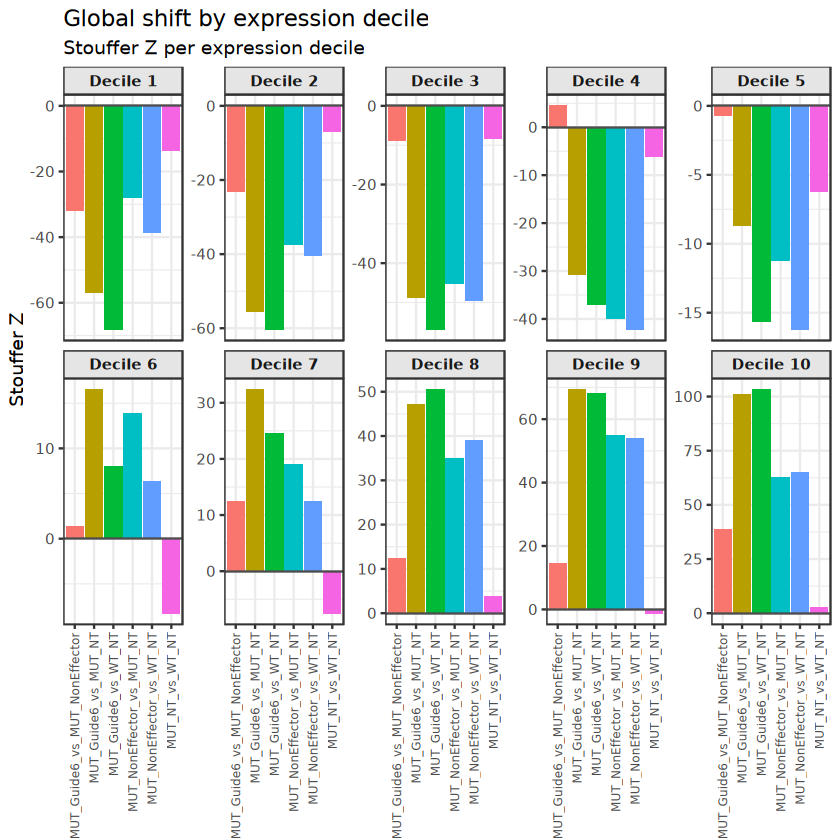

In [25]:
# Plot shift-by-decile
bin_plot <- ggplot(bin_shift,
                   aes(x = contrast, y = stouffer_Z, fill = contrast)) +
  geom_col() +
  geom_hline(yintercept = 0, color = "grey30") +
  facet_wrap(~ decile, ncol = 5, scales = "free_y",
             labeller = labeller(decile = function(x) paste("Decile", x))) +
  labs(title = "Global shift by expression decile",
       subtitle = "Stouffer Z per expression decile",
       x = NULL, y = "Stouffer Z") +
  theme_bw(base_size = 11) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 7),
        legend.position = "none",
        strip.background = element_rect(fill = "grey90"),
        strip.text = element_text(face = "bold"))

# Save
out_file <- file.path(
  out_dir,
  "Shift Based Outputs",
  "shift_by_expression_decile.pdf"
)

ggsave(out_file, bin_plot, width = 14, height = 8)
print(bin_plot)

In [26]:
# Export summary 
summary_wide <- summary_tbl %>%
  select(contrast, median_logFC, mean_logFC, sd_logFC, IQR_logFC,
         stouffer_Z, stouffer_p, prop_up, binom_p_updown, wilcox_p,
         ks_p, pi0_qvalue, prop_true_de, pi0_storey,
         n_p_0.05, n_p_0.01, n_p_0.001,
         n_fdr_0.05, n_fdr_0.10, n_fdr_0.25)

# Save
out_file <- file.path(
  out_dir,
  "Summary Metrics",
  "summary_metrics.csv"
)

write.csv(summary_wide,
          out_file,
          row.names = FALSE)

message("=== Done ===")
message("Outputs written to: ", normalizePath(out_dir))

=== Done ===

Outputs written to: /mnt/c/Users/vicky/Documents/Github/Fink_Ankita_RNAseq_2026/06_Global_Transcriptome

